<div dir="rtl" style="text-align:right">

### جزوه‌ی فارسی Machine Learning | مرحله‌به‌مرحله

این نوت‌بوک هفت مبحث Ensemble Learning را با مثال‌های اجرایی Python پوشش می‌دهد. از دیتاست داخلی Breast Cancer در scikit-learn استفاده می‌کنیم تا نیازی به دانلود داده نباشد.

**پیش‌نیاز:** آشنایی مقدماتی با Python و طبقه‌بندی در Machine Learning.  
**کتابخانه‌های اصلی:** NumPy، Pandas و scikit-learn. XGBoost و LightGBM اختیاری هستند.

</div>

In [9]:
from IPython.display import HTML, display

display(
    HTML("""
<style>
.jp-RenderedHTMLCommon, .jp-MarkdownOutput {
 direction:rtl; text-align:right; font-family:Tahoma,'Segoe UI',sans-serif; line-height:1.9;
}
.jp-RenderedHTMLCommon table { direction:rtl; }
.jp-CodeCell .cm-editor, .jp-CodeCell pre, .jp-InputArea-editor { direction:ltr!important; text-align:left!important; }
</style>
""")
)

<div dir="rtl" style="text-align:right">

## ۰. آماده‌سازی داده

داده را به بخش آموزش و آزمون تقسیم می‌کنیم. مدل فقط با داده‌ی Train آموزش می‌بیند و کیفیت آن را روی Test ارزیابی می‌کنیم.

</div>

In [10]:
# اگر لازم بود:
# %pip install -q numpy pandas scikit-learn xgboost lightgbm

import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Classes:", data.target_names)


Train: (455, 30) | Test: (114, 30)
Classes: ['malignant' 'benign']


<div dir="rtl" style="text-align:right">

## ۲۴. Ensemble Learning Fundamentals — مبانی یادگیری تجمیعی

**Ensemble Learning** ترکیب چند مدل برای ساخت پیش‌بینی نهایی است. معمولاً وقتی مدل‌ها خطاهای متفاوتی داشته باشند، ترکیب آن‌ها سودمندتر است.

- **Voting:** ترکیب رأی یا احتمال مدل‌ها.
- **Bagging:** آموزش مدل‌ها روی نمونه‌گیری‌های مختلف.
- **Boosting:** آموزش ترتیبی برای بهبود خطاهای قبلی.

ابتدا یک درخت تصمیم پایه می‌سازیم تا معیار مقایسه داشته باشیم.

</div>

In [11]:
from sklearn.tree import DecisionTreeClassifier

baseline = DecisionTreeClassifier(random_state=42)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Baseline accuracy:", accuracy_score(y_test, baseline_pred))
print("Baseline F1:", f1_score(y_test, baseline_pred))


Baseline accuracy: 0.9122807017543859
Baseline F1: 0.9285714285714286


<div dir="rtl" style="text-align:right">

## ۲۵. Bagging — نمونه‌گیری و تجمیع

در Bagging چند مدل مستقل روی نمونه‌های Bootstrap از داده‌ی آموزش یاد می‌گیرند. در طبقه‌بندی، خروجی آن‌ها معمولاً با رأی‌گیری ترکیب می‌شود. این روش اغلب واریانس مدل‌های ناپایدار، مانند درخت تصمیم، را کاهش می‌دهد.

`n_estimators` تعداد مدل‌ها و `max_samples` اندازه‌ی نمونه‌ی هر مدل را مشخص می‌کند.

</div>

In [12]:
from sklearn.ensemble import BaggingClassifier

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)
bagging.fit(X_train, y_train)
bag_pred = bagging.predict(X_test)

print("Bagging accuracy:", accuracy_score(y_test, bag_pred))
print("Bagging F1:", f1_score(y_test, bag_pred))


Bagging accuracy: 0.9385964912280702
Bagging F1: 0.9517241379310345


<div dir="rtl" style="text-align:right">

## ۲۶. Boosting — تقویت ترتیبی

در Boosting مدل‌ها یکی پس از دیگری آموزش می‌بینند. مدل جدید سعی می‌کند ضعف مجموعه‌ی قبلی را کاهش دهد؛ بنابراین آموزش مراحل معمولاً مستقل و موازی نیست.

در AdaBoost، نمونه‌هایی که مدل قبلی اشتباه پیش‌بینی کرده، در مراحل بعد وزن بیشتری می‌گیرند.

</div>

In [13]:
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.5,
    random_state=42,
)
adaboost.fit(X_train, y_train)
ada_pred = adaboost.predict(X_test)

print("AdaBoost accuracy:", accuracy_score(y_test, ada_pred))
print("AdaBoost F1:", f1_score(y_test, ada_pred))


AdaBoost accuracy: 0.956140350877193
AdaBoost F1: 0.9659863945578231


<div dir="rtl" style="text-align:right">

## ۲۷. Gradient Boosting — گرادیان بوستینگ

Gradient Boosting مدل را به‌شکل جمعی از یادگیرنده‌های ضعیف، معمولاً درخت‌های کم‌عمق، می‌سازد. هر مرحله مدلی اضافه می‌کند که در جهت کاهش تابع Loss حرکت کند.

پارامترهای مهم:
- `n_estimators`: تعداد مراحل یا درخت‌ها
- `learning_rate`: میزان سهم هر درخت
- `max_depth`: پیچیدگی هر درخت

</div>

In [14]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42,
)
gradient_boosting.fit(X_train, y_train)
gb_pred = gradient_boosting.predict(X_test)

print("Gradient Boosting accuracy:", accuracy_score(y_test, gb_pred))
print("Gradient Boosting F1:", f1_score(y_test, gb_pred))


Gradient Boosting accuracy: 0.9385964912280702
Gradient Boosting F1: 0.9517241379310345


<div dir="rtl" style="text-align:right">

## ۲۸. XGBoost — مبانی

XGBoost یک چارچوب بهینه‌شده‌ی Gradient Boosting درختی است که از امکاناتی مانند regularization و روش‌های کارایی برای آموزش بهره می‌برد. نصب آن اختیاری است.

پارامترهای پرکاربرد:
- `n_estimators`: تعداد درخت‌ها
- `max_depth`: عمق درخت
- `learning_rate`: نرخ یادگیری
- `subsample`: نسبت نمونه‌های انتخاب‌شده برای هر درخت

</div>

In [15]:
# در صورت نیاز:
# %pip install -q xgboost

try:
    from xgboost import XGBClassifier

    xgb_model = XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
    )
    xgb_model.fit(X_train, y_train)
    xgb_pred = xgb_model.predict(X_test)
    print("XGBoost accuracy:", accuracy_score(y_test, xgb_pred))
    print("XGBoost F1:", f1_score(y_test, xgb_pred))
except ImportError:
    print("XGBoost نصب نیست؛ دستور نصب را اجرا کنید.")


XGBoost accuracy: 0.9473684210526315
XGBoost F1: 0.958904109589041


<div dir="rtl" style="text-align:right">

## ۲۹. LightGBM — مبانی

LightGBM چارچوبی برای Gradient Boosting درختی است که بر کارایی آموزش تمرکز دارد. درخت‌ها معمولاً به روش **leaf-wise** رشد می‌کنند؛ این روش می‌تواند کارآمد باشد، اما با تنظیم نامناسب احتمال بیش‌برازش وجود دارد.

پارامترهای مهم:
- `n_estimators`
- `learning_rate`
- `num_leaves`: تعداد برگ‌ها
- `max_depth`: محدودیت عمق

</div>

In [16]:
# در صورت نیاز:
# %pip install -q lightgbm

try:
    from lightgbm import LGBMClassifier

    lgbm_model = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=-1,
        random_state=42,
        verbosity=-1,
    )
    lgbm_model.fit(X_train, y_train)
    lgbm_pred = lgbm_model.predict(X_test)
    print("LightGBM accuracy:", accuracy_score(y_test, lgbm_pred))
    print("LightGBM F1:", f1_score(y_test, lgbm_pred))
except ImportError:
    print("LightGBM نصب نیست؛ دستور نصب را اجرا کنید.")


LightGBM accuracy: 0.9649122807017544
LightGBM F1: 0.9726027397260274


<div dir="rtl" style="text-align:right">

## ۳۰. Feature Importance — اهمیت ویژگی‌ها

Feature Importance نشان می‌دهد کدام ویژگی‌ها در پیش‌بینی مدل نقش بیشتری داشته‌اند. در مدل‌های درختی معمولاً می‌توان این مقدار را مستقیماً دریافت کرد.

**توجه:** اهمیت بالا اثبات‌کننده‌ی رابطه‌ی علت‌ومعلولی نیست. همچنین روش‌های مبتنی بر درخت ممکن است به بعضی ویژگی‌ها سوگیری داشته باشند. برای تحلیل مکمل می‌توان از Permutation Importance یا SHAP استفاده کرد.

</div>

,feature,importance
27,worst concave points,0.315771
20,worst radius,0.274245
7,mean concave points,0.144424
22,worst perimeter,0.117707
23,worst area,0.052221
21,worst texture,0.025905
11,texture error,0.017592
13,area error,0.014801
16,concavity error,0.012682
1,mean texture,0.005086


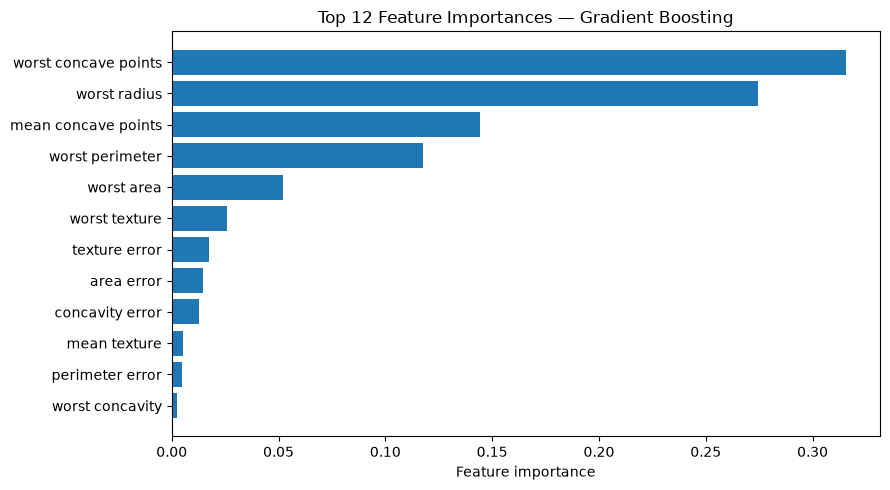

In [17]:
import matplotlib.pyplot as plt

importance_df = (
    pd.DataFrame(
        {
            "feature": data.feature_names,
            "importance": gradient_boosting.feature_importances_,
        }
    )
    .sort_values("importance", ascending=False)
    .head(12)
)

display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(importance_df["feature"][::-1], importance_df["importance"][::-1])
plt.xlabel("Feature importance")
plt.title("Top 12 Feature Importances — Gradient Boosting")
plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align:right">

## مقایسه‌ی مدل‌ها

این جدول معیارهای مدل‌هایی را که اجرا شده‌اند روی یک Test set مقایسه می‌کند. برای انتخاب نهایی بهتر است از Cross-Validation استفاده کنید؛ یک تقسیم‌بندی به‌تنهایی ممکن است نتیجه‌ی ناپایداری بدهد.

</div>

In [18]:
models = {
    "Decision Tree": baseline,
    "Bagging": bagging,
    "AdaBoost": adaboost,
    "Gradient Boosting": gradient_boosting,
}
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "F1": f1_score(y_test, pred),
        }
    )

display(pd.DataFrame(rows).sort_values("F1", ascending=False))


,Model,Accuracy,F1
2,AdaBoost,0.956140,0.965986
1,Bagging,0.938596,0.951724
3,Gradient Boosting,0.938596,0.951724
0,Decision Tree,0.912281,0.928571


<div dir="rtl" style="text-align:right">

## جمع‌بندی و تمرین

- **Bagging:** آموزش مستقل روی نمونه‌های مختلف و تجمیع خروجی.
- **Boosting:** آموزش ترتیبی برای بهبود خطا.
- **Gradient Boosting:** اضافه کردن مدل‌ها در جهت کاهش Loss.
- **XGBoost و LightGBM:** ابزارهای شناخته‌شده‌ی Gradient Boosting.
- **Feature Importance:** ابزار بررسی نقش ویژگی‌ها، نه اثبات علت.

### تمرین‌های کوتاه
1. در Bagging مقدار `n_estimators` را به 30 و سپس 200 تغییر بده.
2. `learning_rate` را کمتر و `n_estimators` را بیشتر کن؛ نتایج Gradient Boosting را مقایسه کن.
3. با `StratifiedKFold` و Cross-Validation ارزیابی را تکرار کن.
4. در LightGBM مقدار `num_leaves` را تغییر بده و اثرش را بر F1 بررسی کن.
5. Feature Importance را با Permutation Importance مقایسه کن.

### منابع رسمی
- [scikit-learn — Ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html)
- [XGBoost — Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html)
- [LightGBM — Python API](https://lightgbm.readthedocs.io/en/stable/Python-API.html)
- [scikit-learn — Permutation Importance](https://scikit-learn.org/stable/modules/permutation_importance.html)

</div>